# 3장 위계 동역학 모델 (실습)

이 노트북은 위계 생성 모델에 대한 이론의 주장 다섯 가지를 숫자로 확인한다.

1. 위층으로 갈수록 느린 시간 척도를 다루는가?
2. 위계 자유 에너지를 경사 하강으로 줄이면 정확한 베이즈 사후에 닿는가?
3. 위층이 아래층의 사전 믿음을 스스로 만들면 추정이 정말 나아지는가?
4. 예측할 수 있는 입력은 위로 아무것도 보내지 않는가?
5. 정밀도가 위에서 내려온 예측과 아래에서 올라온 감각의 무게를 정하는가?

마지막에는 틀린 사전 믿음이 지나치게 정밀할 때 지각이 어떻게 실패하는지 본다.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import koreanize_matplotlib  # 한글 글꼴과 마이너스 기호 설정
from scipy.linalg import cholesky, toeplitz

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.figsize": (6.4, 3.2), "figure.dpi": 200,
                     "axes.spines.top": False, "axes.spines.right": False})

def makeNoise(C, s2, t):
    """공분산 C, 매끄러움 s2 인 유색 잡음 (2장과 같은 함수)."""
    C = np.atleast_2d(C)
    w = cholesky(C, lower=True) @ np.random.randn(C.shape[1], np.size(t))
    if s2 < 1e-5:
        return w
    P = toeplitz(np.exp(-t**2 / (2 * s2)))
    return w @ (P @ np.diag(1 / np.sqrt(np.diag(P.T @ P))))

print("준비 완료, numpy", np.__version__)

준비 완료, numpy 2.5.4


## 1. 위계 생성 모델에서 표본을 뽑는다

세 단의 위계 동역학 모델을 생성 과정으로 굴린다. 맨 위의 원인 v⁽²⁾ 는 5 초 주기로 천천히 바뀌는 맥락이다. 2층의 숨은 상태는 1 Hz 로 도는 진동자이고, 2층의 출력 v⁽¹⁾ 는 맥락에 그 진동을 얹은 것이다. 1층의 숨은 상태는 4 Hz 로 도는 진동자이고, 감각 y 는 v⁽¹⁾ 에 그 빠른 진동과 잡음을 얹은 것이다. 층마다 주파수 무게중심을 잰다.

In [2]:
dt = 0.005
t = np.arange(0, 5 + dt / 2, dt)
N = t.size
v2 = np.sin(2 * np.pi * 0.2 * t)                     # 맨 위의 느린 맥락
z2, z1 = makeNoise(0.002, 1 / 64, t)[0], makeNoise(0.01, 1 / 512, t)[0]

def oscillator(freq, amp):
    """x'' = -(2πf)² x 를 오일러 방법으로 적분한 숨은 상태 (진폭 amp)."""
    om, a, b = 2 * np.pi * freq, np.zeros(N), np.zeros(N)
    a[0] = amp
    for i in range(N - 1):
        a[i + 1] = a[i] + dt * om * b[i]
        b[i + 1] = b[i] - dt * om * a[i + 1]
    return a

v1 = v2 + oscillator(1.0, 0.4) + z2                  # 2층 출력 = 1층의 원인
y = v1 + oscillator(4.0, 0.3) + z1                   # 감각

def centroid(sig):
    """신호의 주파수 무게중심 (Hz). 클수록 빨리 변한다."""
    s = sig - sig.mean()
    P = np.abs(np.fft.rfft(s))**2
    f = np.fft.rfftfreq(s.size, dt)
    return (f * P).sum() / P.sum()

for name, sig in [("맨 위 v(2)", v2), ("2층 출력 v(1)", v1), ("감각 y", y)]:
    print(f"{name:11s} 주파수 무게중심 {centroid(sig):5.2f} Hz")

맨 위 v(2)    주파수 무게중심  0.20 Hz
2층 출력 v(1)  주파수 무게중심  0.32 Hz
감각 y        주파수 무게중심  0.60 Hz


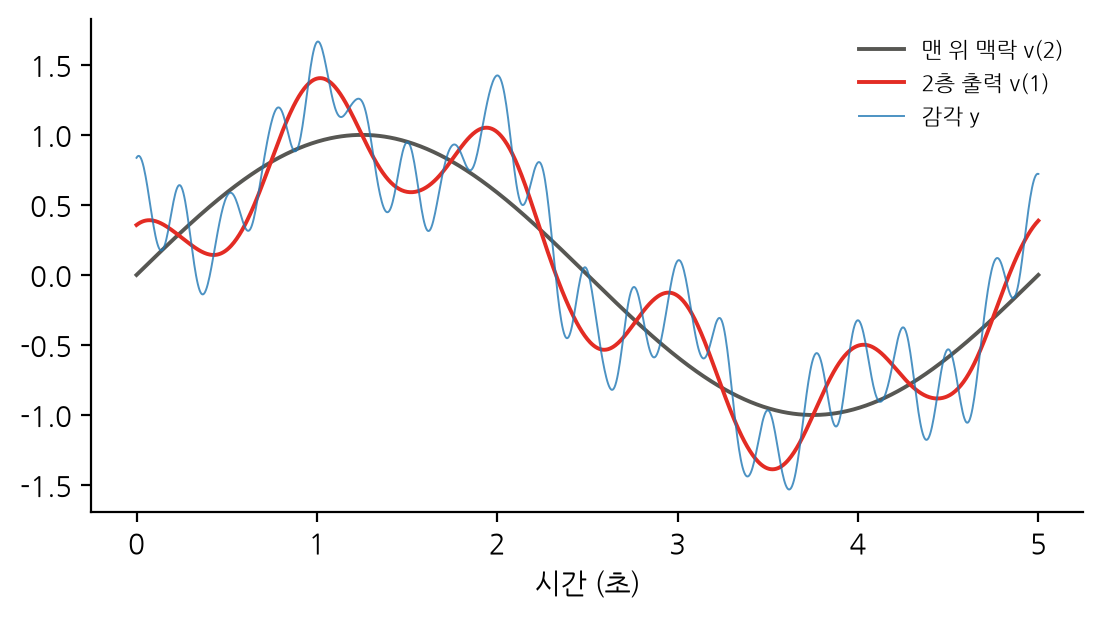

In [3]:
plt.plot(t, v2, color="#575753", lw=1.4, label="맨 위 맥락 v(2)")
plt.plot(t, v1, color="#E32C24", lw=1.4, label="2층 출력 v(1)")
plt.plot(t, y, color="#1f77b4", lw=0.7, alpha=0.8, label="감각 y")
plt.xlabel("시간 (초)")
plt.legend(frameon=False, fontsize=8, loc="upper right")
plt.show()

## 2. 두 층 위계에서 추론한다

정적인 두 층 선형 위계를 쓴다. 맨 위의 원인 v₂ 에 사전 믿음 N(η, σ_v²) 가 있고, 1층의 원인은 v₁ = 2v₂ + z₂, 감각은 y = v₁ + z₁ 이다. 자유 에너지는 층마다의 정밀도 가중 예측 오차 제곱합이다. 경사 하강으로 μ₁, μ₂ 를 찾고 기준선인 닫힌 꼴 사후 평균과 비교한다.

In [4]:
eta, s2_v = 1.0, 1.0          # 맨 위 사전 믿음
s2_z2, s2_z1 = 0.5, 0.5       # 2층 → 1층 잡음, 감각 잡음
y_obs = 3.5

def errors(m1, m2, y=y_obs):
    return y - m1, m1 - 2 * m2, m2 - eta          # 감각, 층 사이, 맨 위 사전

def F(m1, m2, y=y_obs, s1=s2_z1, s2=s2_z2, sv=s2_v):
    e1, e2, e3 = errors(m1, m2, y)
    return e1**2 / (2 * s1) + e2**2 / (2 * s2) + e3**2 / (2 * sv)

def infer(y=y_obs, s1=s2_z1, s2=s2_z2, sv=s2_v, steps=3000, lr=0.02, trace=False):
    m1, m2, hist = 2 * eta, eta, []               # 믿음은 위층의 예측에서 출발
    for _ in range(steps):
        e1, e2, e3 = errors(m1, m2, y)
        d1 = -e1 / s1 + e2 / s2                    # ∂F/∂μ1
        d2 = -2 * e2 / s2 + e3 / sv                # ∂F/∂μ2
        m1, m2 = m1 - lr * d1, m2 - lr * d2
        hist.append((e1 / s1, 2 * m2, m1))         # 올라가는 오차, 내려오는 예측, 믿음
    return (m1, m2, np.array(hist)) if trace else (m1, m2)

# 기준선: 선형-가우스이므로 정밀도 행렬을 풀어 정확한 사후 평균을 얻는다
P = np.array([[1 / s2_z1 + 1 / s2_z2, -2 / s2_z2], [-2 / s2_z2, 4 / s2_z2 + 1 / s2_v]])
b = np.array([y_obs / s2_z1, eta / s2_v])
exact = np.linalg.solve(P, b)
m1, m2 = infer()
print(f"경사 하강 μ1 = {m1:.4f}, μ2 = {m2:.4f}")
print(f"정확한 사후 μ1 = {exact[0]:.4f}, μ2 = {exact[1]:.4f}")
print(f"최소 자유 에너지 (상수 제외) = {F(m1, m2):.4f}")

경사 하강 μ1 = 3.3500, μ2 = 1.6000
정확한 사후 μ1 = 3.3500, μ2 = 1.6000
최소 자유 에너지 (상수 제외) = 0.2250


## 3. 위계는 스스로 사전 믿음을 만든다

아이가 공을 여덟 번 던진다. 던질 때마다 거리 v₁ₖ 는 그 아이의 평소 거리 v₂ 근처에서 흩어지고(분산 1), 눈으로 본 거리 yₖ 에는 잡음이 섞인다(분산 2). 평소 거리 v₂ 는 아이마다 다르고 미리 알지 못한다.

- 평평한 모델(기준선): 던질 때마다 따로, 넓은 사전 믿음 N(0, 101) 으로 추정한다.
- 위계 모델: 여덟 번의 관측으로 v₂ 를 함께 추정하고, 그것을 각 v₁ₖ 의 사전 믿음으로 쓴다.

2000 명의 아이를 흉내 내어 두 모델의 추정 오차(RMSE)를 잰다.

In [5]:
rng = np.random.default_rng(3)
T_, K = 2000, 8
tau2, sig2, prior2 = 1.0, 2.0, 100.0                  # 던지기 흩어짐, 시각 잡음, 맨 위 사전 분산
v2_true = rng.normal(0, np.sqrt(prior2), T_)
v1_true = v2_true[:, None] + rng.normal(0, np.sqrt(tau2), (T_, K))
y_k = v1_true + rng.normal(0, np.sqrt(sig2), (T_, K))

# 평평한 모델: 던질 때마다 따로 N(0, prior2 + tau2) 사전
flat = y_k * (prior2 + tau2) / (prior2 + tau2 + sig2)

# 위계 모델: 자유 에너지 경사 하강 (모든 아이를 한꺼번에)
m1, m2 = y_k.copy(), y_k.mean(1)
for _ in range(4000):
    e1, e2, e3 = y_k - m1, m1 - m2[:, None], m2 - 0.0
    m1 -= 0.05 * (-e1 / sig2 + e2 / tau2)
    m2 -= 0.05 * (-e2.sum(1) / tau2 + e3 / prior2)

rmse = lambda est: np.sqrt(((est - v1_true)**2).mean())
print(f"관측 그대로 쓰기   RMSE {rmse(y_k):.3f}")
print(f"평평한 모델        RMSE {rmse(flat):.3f}")
print(f"위계 모델          RMSE {rmse(m1):.3f}")
print(f"위계 모델의 평소 거리 추정 오차 {np.sqrt(((m2 - v2_true)**2).mean()):.3f}")

관측 그대로 쓰기   RMSE 1.411
평평한 모델        RMSE 1.396
위계 모델          RMSE 0.912
위계 모델의 평소 거리 추정 오차 0.615


## 4. 위로는 예측 오차만 올라간다

두 경우를 비교한다. 하나는 위층의 예측과 어긋나는 감각(y = 3.5), 다른 하나는 위층이 예측한 그대로의 감각(y = 2η = 2)이다. 추론이 진행되는 동안 위로 올라가는 정밀도 가중 감각 오차 ξ₁ = ε₁/σ₁² 와 아래로 내려오는 예측 2μ₂ 를 기록한다.

In [6]:
for y_case in [3.5, 2 * eta]:
    _, _, h = infer(y=y_case, trace=True)
    print(f"y = {y_case:.1f}:  처음 ξ1 = {h[0, 0]:+.3f}  10걸음 ξ1 = {h[9, 0]:+.3f}  "
          f"끝 ξ1 = {h[-1, 0]:+.3f}  끝 예측 2μ2 = {h[-1, 1]:.3f}")

y = 3.5:  처음 ξ1 = +3.000  10걸음 ξ1 = +2.169  끝 ξ1 = +0.300  끝 예측 2μ2 = 3.200
y = 2.0:  처음 ξ1 = +0.000  10걸음 ξ1 = +0.000  끝 ξ1 = +0.000  끝 예측 2μ2 = 2.000


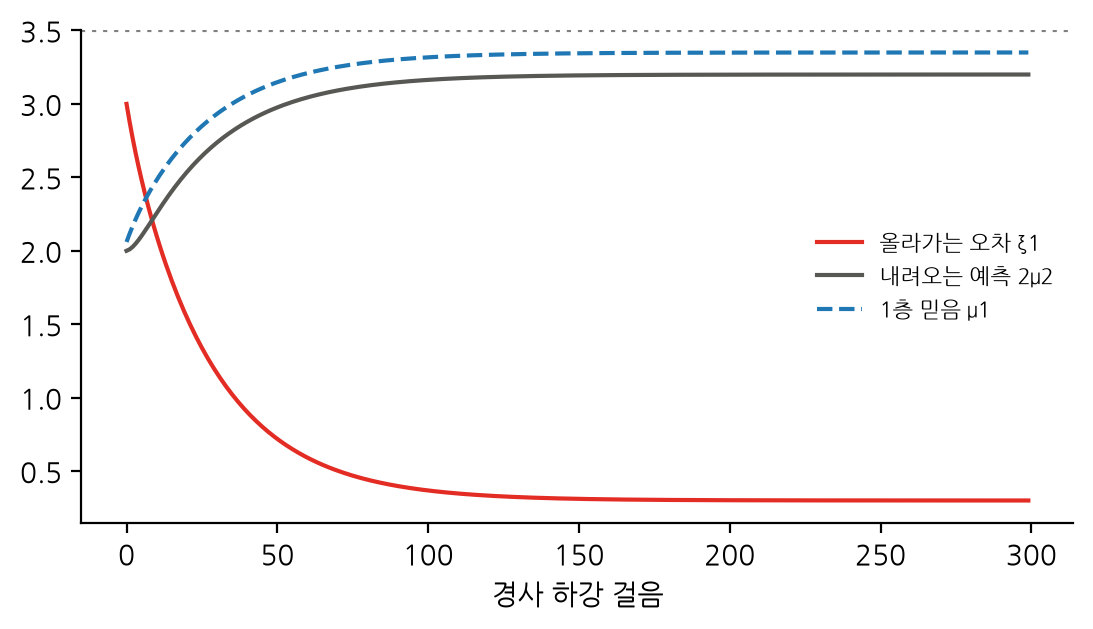

In [7]:
_, _, h = infer(y=3.5, trace=True, steps=300)
fig, ax = plt.subplots()
ax.plot(h[:, 0], color="#E32C24", label="올라가는 오차 ξ1")
ax.plot(h[:, 1], color="#575753", label="내려오는 예측 2μ2")
ax.plot(h[:, 2], "--", color="#1f77b4", label="1층 믿음 μ1")
ax.axhline(3.5, ls=":", color="gray")
ax.set_xlabel("경사 하강 걸음")
ax.legend(frameon=False, fontsize=8)
plt.show()

## 5. 정밀도가 위아래의 무게를 정한다

감각 잡음 분산 σ₁² 만 바꿔 가며 1층 믿음 μ₁ 이 어디에 서는지 본다. 감각은 3.5 이고, 위에서 내려온 예측은 대략 2 근처다.

In [8]:
print("감각 분산  μ1      위에서 온 예측 2μ2")
for s1 in [0.05, 0.5, 2.0, 10.0]:
    m1, m2 = infer(s1=s1)
    print(f"{s1:7.2f}  {m1:6.3f}  {2 * m2:6.3f}")

감각 분산  μ1      위에서 온 예측 2μ2
   0.05   3.484   3.319
   0.50   3.350   3.200
   2.00   3.038   2.923
  10.00   2.466   2.414


## 6. 실패 조건 — 틀렸는데 확신하는 사전 믿음

맨 위 사전 믿음이 η = −2 로 틀렸다고 하자. 그 확신의 정도(σ_v²)와 층 사이 연결의 정밀도(σ₂²)를 바꿔 가며, 같은 감각 y = 3.5 에서 1층 믿음과 남은 감각 오차, 그리고 최소 자유 에너지를 잰다.

In [9]:
eta_saved, eta = eta, -2.0
print("사전 분산  층사이 분산   μ1      남은 감각 오차   최소 F")
for sv, s2 in [(1.0, 0.5), (0.1, 0.5), (0.01, 0.05), (0.001, 0.01)]:
    m1, m2 = infer(sv=sv, s2=s2, steps=20000, lr=0.0005)
    print(f"{sv:8.3f}  {s2:9.2f}   {m1:6.3f}   {y_obs - m1:12.3f}   {F(m1, m2, s2=s2, sv=sv):7.2f}")
eta = eta_saved

사전 분산  층사이 분산   μ1      남은 감각 오차   최소 F
   1.000       0.50    2.750          0.750      5.63
   0.100       0.50    0.821          2.679     20.09
   0.010       0.05   -2.856          6.356     47.67
   0.001       0.01   -3.796          7.296     54.72


## 결론

- 위층으로 갈수록 신호의 주파수 무게중심이 낮아진다. 위계는 시간 척도의 위계이기도 하다.
- 층마다의 정밀도 가중 예측 오차를 더한 위계 자유 에너지를 경사 하강으로 줄이면 정확한 베이즈 사후에 닿는다.
- 여러 관측이 같은 위층 원인을 공유하면, 위계 모델이 그 원인을 추정해 사전 믿음으로 쓰면서 개별 추정 오차가 평평한 모델보다 줄어든다.
- 위층의 예측과 맞는 감각은 처음부터 위로 오차를 보내지 않는다. 위로 흐르는 것은 예측하지 못한 부분뿐이다.
- 감각이 정밀하면 믿음은 감각 쪽에, 흐리면 위에서 내려온 예측 쪽에 선다.
- 틀린 사전 믿음을 지나치게 정밀하게 들고 있으면 지각은 감각을 무시하고 기대 쪽에 선다. 그 대가로 큰 예측 오차와 높은 자유 에너지가 남는다.